# D15 独立实操

先读knowledge.md。先写预期结果，再写代码；不要从reference整段复制。最后从空白完成读取到保存全过程。


## 1. 先手算四个价格，确认正负号

先在纸上写100→90→108→81。除以第一个价格100，净值依次为1、0.90、1.08、0.81。
历史峰值只查看当前及之前的净值，依次为1、1、1.08、1.08。
回撤=当前净值/截至当期峰值−1，依次为0、−10%、0、−25%。
108创新高时回撤为0，81相对108下降25%。最大回撤负值是−25%，其幅度为正的25%。
末期相对起点100的累计收益是81/100−1=−19%，与最大回撤不是同一个量。


In [1]:
# 在这里先写预计结果，再独立写代码。
# 每一步运行后对照上一节的口径，保持统一使用prices。
import pandas as pd  # pandas用于表格和序列计算，简称pd

demo = pd.DataFrame({"price": [100, 90, 108, 81]})  # 四个价格构成一列
demo["wealth"] = demo["price"] / demo["price"].iloc[0]  # iloc[0]取首条价格；净值从1开始
demo["peak"] = demo["wealth"].cummax()  # cummax：从开头到当前行的累计最大值
demo["drawdown"] = demo["wealth"] / demo["peak"] - 1  # 回撤采用非正值口径
demo_signed_min = demo["drawdown"].min()  # min取最负的回撤，预计-0.25
demo_mdd = -demo_signed_min  # mdd是maximum drawdown缩写，此处用正的幅度0.25

print(demo)  # 先对照自己手算的四行
print(f"最大回撤负值：{demo_signed_min:.2%}")  # .2%只格式化显示为-25.00%
print(f"最大回撤幅度：{demo_mdd:.2%}")  # 预计25.00%，变量内部仍为0.25
assert abs(demo_mdd - 0.25) < 1e-12  # abs为绝对值；容许极小浮点误差


   price  wealth  peak  drawdown
0    100    1.00  1.00      0.00
1     90    0.90  1.00     -0.10
2    108    1.08  1.08      0.00
3     81    0.81  1.08     -0.25
最大回撤负值：-25.00%
最大回撤幅度：25.00%


## 2. 从原CSV重新读取并检查

输入是与D14相同的12行3列模拟价格，A/B各六条。仅沿用原始CSV，不使用D14 Notebook的旧变量。
所有转换从raw自己的列读取、写回raw；后续统一使用prices这一张表，不混用line。
假设价格口径一致、无拆股分红且完整为正。日期为教学观测日期，不是真实市场数据。


In [5]:
# 在这里先写预计结果，再独立写代码。
# 每一步运行后对照上一节的口径，保持统一使用prices。
import pandas as pd
from pathlib import Path
base_dir = Path("D:/Learning/study/d15")  # 今天的练习目录

raw = pd.read_csv(base_dir / "data" / "prices.csv")  # 读取原始价格表

raw["date"] = pd.to_datetime(
    raw["date"],
    format = "%Y-%m-%d",
    errors = "coerce",
)
raw["price"] = pd.to_numeric(
    raw["price"],
    errors = "coerce",
)
assert raw[["asset","date","price"]].notna().all().all()
duplicate_key = raw.duplicated(
    subset = ["asset","date"],
    keep = False,
)
assert not duplicate_key.any()
assert (raw["price"] > 0).all()

prices = raw.sort_values(
    ["asset","date"]
).reset_index(drop=True)

print(prices)
print(prices.shape)


   asset       date  price
0      A 2026-10-12    100
1      A 2026-10-13    110
2      A 2026-10-14     99
3      A 2026-10-15    105
4      A 2026-10-16    102
5      A 2026-10-19    108
6      B 2026-10-12    200
7      B 2026-10-13    190
8      B 2026-10-14    209
9      B 2026-10-15    205
10     B 2026-10-16    210
11     B 2026-10-19    215
(12, 3)


## 3. 收益标准差：仅使用五个有效收益

先在各资产内部计算相邻观测收益；每个资产首条没有上一条价格，因此保持NaN。
std是standard deviation（标准差）的缩写。这里对收益率求标准差，不是对价格求。
ddof是delta degrees of freedom（自由度修正）的缩写；ddof=1使用n−1作方差分母，再开平方。
Pandas的std默认ddof=1且排除缺失值；这里仍显式写出，便于核对。每个资产n=5，不是6。
不要把首条收益fillna(0)，也不乘sqrt(252)。本课结果只称非年化相邻观测收益标准差。


In [8]:
# 在这里先写预计结果，再独立写代码。
# 每一步运行后对照上一节的口径，保持统一使用prices。
prices["return_pct"] = prices.groupby("asset")["price"].pct_change(
    fill_method = None,
)
return_count = prices.groupby("asset")["return_pct"].count()
return_std = prices.groupby("asset")["return_pct"].std(
    ddof = 1
)
print(prices[["asset", "date", "price", "return_pct"]])  # 每个资产首行收益仍应是NaN
print(return_count)  # 预计A=5、B=5
for asset, value in return_std.items():  # items依次取出资产标签和对应标准差
    print(asset, f"非年化收益标准差：{value:.4%}")  # 预计A约8.1084%，B约5.6520%
    # 以百分数显示，保留4位小数

   asset       date  price  return_pct
0      A 2026-10-12    100         NaN
1      A 2026-10-13    110    0.100000
2      A 2026-10-14     99   -0.100000
3      A 2026-10-15    105    0.060606
4      A 2026-10-16    102   -0.028571
5      A 2026-10-19    108    0.058824
6      B 2026-10-12    200         NaN
7      B 2026-10-13    190   -0.050000
8      B 2026-10-14    209    0.100000
9      B 2026-10-15    205   -0.019139
10     B 2026-10-16    210    0.024390
11     B 2026-10-19    215    0.023810
asset
A    5
B    5
Name: return_pct, dtype: int64
A 非年化收益标准差：8.1084%
B 非年化收益标准差：5.6520%


## 4. 每个资产首价归一化为1

transform("first")把本资产首条价格放回本组每一行，因此返回12项，不是两项。
本例关键字段已检查没有缺失，所以first取到的第一项就是首条价格。
wealth是归一化价格净值，含义为当前价格相对本组首价的倍数。
此处从完整价格直接计算；不会用首条未知收益填0，也不会受到旧累计列的影响。


In [11]:
first_price = prices.groupby("asset")["price"].transform("first")  # A组每行为100，B组每行为200，长度仍为12
prices["wealth"] = prices["price"] / first_price  # 每行除以本资产首价，各资产第一行恰好为1

print(prices[["asset", "date", "price", "wealth"]])  # A末期1.08，B末期1.075


   asset       date  price  wealth
0      A 2026-10-12    100   1.000
1      A 2026-10-13    110   1.100
2      A 2026-10-14     99   0.990
3      A 2026-10-15    105   1.050
4      A 2026-10-16    102   1.020
5      A 2026-10-19    108   1.080
6      B 2026-10-12    200   1.000
7      B 2026-10-13    190   0.950
8      B 2026-10-14    209   1.045
9      B 2026-10-15    205   1.025
10     B 2026-10-16    210   1.050
11     B 2026-10-19    215   1.075


## 5. 组内历史峰值与回撤

cummax每行给出“截至当前行”的最高净值，包括当前行。创新高或回到峰值时，回撤为0。
必须groupby("asset")后cummax，避免A的历史影响B；也不能用全期max代替，后者会用到未来价格。
drawdown列保留0或负值；不对它整体取绝对值后还把图叫作负值回撤图。
价格比值回撤与净值回撤相同，因为对同一个资产，分子分母都除以相同首价。


In [12]:
# 在这里先写预计结果，再独立写代码。
# 每一步运行后对照上一节的口径，保持统一使用prices。
prices["peak"] = prices.groupby("asset")["wealth"].cummax()
prices["drawdown"] = prices["wealth"]/prices["peak"] -1

print(prices[["asset", "date", "wealth", "peak", "drawdown"]])  # 检查峰值不下降、回撤不为正
assert (prices["drawdown"] <= 1e-12).all()  # 容许计算误差；本完整正价样本回撤应不大于0


   asset       date  wealth   peak  drawdown
0      A 2026-10-12   1.000  1.000  0.000000
1      A 2026-10-13   1.100  1.100  0.000000
2      A 2026-10-14   0.990  1.100 -0.100000
3      A 2026-10-15   1.050  1.100 -0.045455
4      A 2026-10-16   1.020  1.100 -0.072727
5      A 2026-10-19   1.080  1.100 -0.018182
6      B 2026-10-12   1.000  1.000  0.000000
7      B 2026-10-13   0.950  1.000 -0.050000
8      B 2026-10-14   1.045  1.045  0.000000
9      B 2026-10-15   1.025  1.045 -0.019139
10     B 2026-10-16   1.050  1.050  0.000000
11     B 2026-10-19   1.075  1.075  0.000000


## 6. 汇总风险口径，区分负值与正幅度

每个资产汇成一行，summary为两行。最深回撤取min，不取max；max通常只是0。
标准差Series与汇总表都以asset为索引，所以给新列赋值时按资产标签自动对齐。
return_std不是亏损概率，不能从8.1084%推出“有8.1084%的概率亏损”。
最大回撤只描述本样本已观察到的价格路径，不代表样本开始以前的高点或未观测到的盘中路径。


In [17]:
summary = prices.groupby("asset").agg(  # 每个资产聚合为一行；括号中的名称是自己给结果列起的名字
    price_count=("price", "size"),  # size统计本组记录行数，预计6
    return_count=("return_pct", "count"),  # count统计非空收益数，预计5
    min_drawdown=("drawdown", "min"),  # min取本组最深的负回撤
)  # summary暂以asset为索引

summary["return_std"] = return_std  # 放入前面算好的非年化样本标准差，按资产索引对齐
summary["max_drawdown_magnitude"] = -summary["min_drawdown"]  # 将最负回撤取负号，得到正的最大回撤幅度

print(summary)  # A幅度0.10，B幅度0.05；不要提前把这些小数改成10和5
for asset, row in summary.iterrows():  # iterrows逐行取出资产标签和一行结果，这里仅用于两行展示
    print(asset, f"最大回撤负值：{row['min_drawdown']:.2%}", f"幅度：{row['max_drawdown_magnitude']:.2%}")  # 格式化显示


       price_count  return_count  min_drawdown  return_std  \
asset                                                        
A                6             5         -0.10    0.081084   
B                6             5         -0.05    0.056520   

       max_drawdown_magnitude  
asset                          
A                        0.10  
B                        0.05  
A 最大回撤负值：-10.00% 幅度：10.00%
B 最大回撤负值：-5.00% 幅度：5.00%


## 7. 画负值回撤曲线，并另存结果

横轴是观测日期，纵轴使用百分数；图标题和纵轴同时写清drawdown<=0（回撤为非正值）。
PercentFormatter(xmax=1)把1显示成100%，所以直接传小数回撤，不再乘100。
Matplotlib的英文标签可以避免当前机器中文字体缺字。图例A/B分别对应两条资产曲线。
导出risk_detail.csv为12行7列，risk_summary.csv为2行6列；CSV内百分率仍存小数。


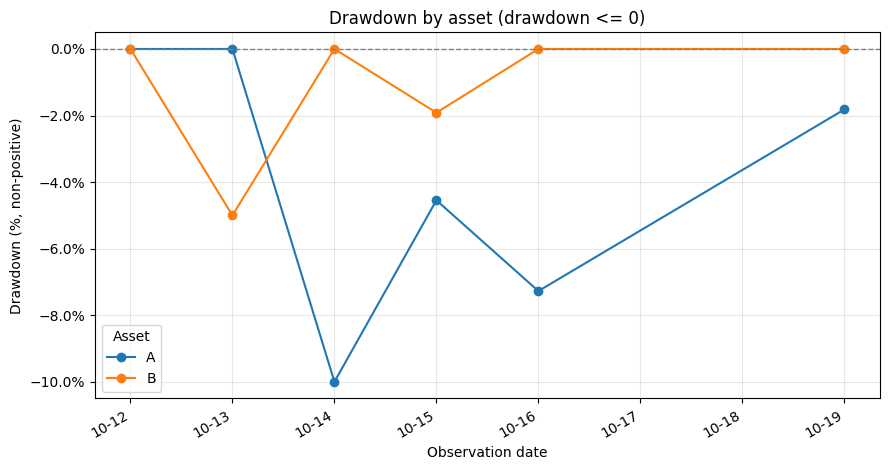

已保存： D:\Learning\study\d15\outputs


In [18]:
# 在这里先写预计结果，再独立写代码。
# 每一步运行后对照上一节的口径，保持统一使用prices。
import matplotlib.pyplot as plt  # pyplot是Matplotlib的绘图接口，简称plt
import matplotlib.dates as mdates  # dates是日期刻度工具，简称mdates
from matplotlib.ticker import PercentFormatter  # 用于把小数坐标显示为百分数

output_dir = base_dir / "outputs"  # output_dir表示输出文件夹路径
output_dir.mkdir(parents=True, exist_ok=True)  # 缺少父文件夹就一起创建；已有时不报错
fig, ax = plt.subplots(figsize=(9, 4.8))  # 创建一张画布fig和一个坐标区域ax，尺寸单位为英寸
for asset, group in prices.groupby("asset"):  # 每轮group是一种资产的六行子表
    ax.plot(group["date"], group["drawdown"], marker="o", label=asset)  # 画该资产的非正值回撤，保留小数
ax.axhline(0, color="gray", linestyle="--", linewidth=1)  # 添加0%参考线
ax.set_title("Drawdown by asset (drawdown <= 0)")  # 标题说明回撤采用非正值
ax.set_xlabel("Observation date")  # 横轴为观测日期
ax.set_ylabel("Drawdown (%, non-positive)")  # 纵轴单位和正负号口径
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))  # 0.10显示10%，-0.10显示-10%
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))  # 日期标签显示月-日
ax.legend(title="Asset")  # 根据每条plot的label显示资产图例
ax.grid(alpha=0.3)  # 网格用较浅的透明度，便于读数
fig.autofmt_xdate(rotation=30)  # 旋转日期文字，减少重叠
fig.tight_layout()  # 调整布局，避免标题或坐标标签被挤出画布
fig.savefig(output_dir / "drawdown.png", dpi=150, bbox_inches="tight")  # 保存PNG图像
plt.show()  # 在Notebook中显示这张图

prices.to_csv(output_dir / "risk_detail.csv", index=False, encoding="utf-8-sig")  # 保存12行明细，不导出默认索引
summary.reset_index().to_csv(output_dir / "risk_summary.csv", index=False, encoding="utf-8-sig")  # 资产索引转为列后保存
demo.to_csv(output_dir / "drawdown_check.csv", index=False, encoding="utf-8-sig")  # 保存四价格手算核对表
print("已保存：", output_dir)  # 查看CSV与PNG所在文件夹


## 8. 有效括号与栈

手写([])、([)]、(()、)(的栈。独立定义is_valid(s)，至少检查正确嵌套、错序、少右括号、首个字符是右括号。参考stack_practice.md和20_review.py。


In [ ]:
# 在这里独立写is_valid和样例检查；return not stack应位于for循环外。


## 9. 关掉参考，独立验收

重新读原CSV，从头得到非年化收益std、首价净值、组内peak和drawdown、两行汇总、负值曲线。自己的输出另存independent_前缀。解释A/B为什么各5个收益以及最大回撤幅度为何10%/5%。最后回答notes.md。


In [ ]:
# 从空白重新开始，最后用A/B的手算结果核对。
